In [ ]:
!pip install numpy==2.2.6
!pip install -q astroquery gala galstreams

from __future__ import annotations

import sys
import hashlib
import json
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import requests

from astroquery.gaia import Gaia
import astropy.coordinates as coord
import astropy.units as u
import galstreams
import gala.potential as gp
import gala.dynamics as gd
from gala.units import galactic
from gala.dynamics import mockstream as ms


In [4]:
SIM = "TNG50-1"
SNAP = 99  # z = 0
BASE_URL = f"http://www.tng-project.org/api/{SIM}/snapshots/{SNAP}/"
API_KEY = "fb0a2a4f6b517ee45f49a4321f51b4c9 "

# TNG cosmology parameters
H_HUBBLE = 0.6774
A_SCALE = 1.0  # snapshot 99 is z = 0

# Default selection cuts
# MW-analog hosts: select on the central subhalo's total bound mass, which
# corresponds to roughly the same number for the FoF group's DM mass. Range
# straddles canonical MW estimates (1.0-1.5e12) and slightly heavier analogs.
MW_HALO_MASS_MSUN = (1.0e12, 2.0e12)
PERTURBER_MASS_MSUN = (1.0e6, 1.0e9)
PERTURBER_R_RANGE_KPC = (10.0, 100.0)



# Stream-perturbation defaults
DEFAULT_STREAM_AGE_GYR = 3
DEFAULT_V_REL_KMS = 200.0
DEFAULT_BMAX_OVER_RS = 5.0
KPC_PER_KMS_GYR = 1.02271  # 1 km/s * 1 Gyr in kpc

# On-disk layout
DATA_DIR = Path.cwd() / "illustris_data"
API_CACHE_DIR = DATA_DIR / "api_cache"
HALO_CACHE_DIR = DATA_DIR / "halos"
DOWNLOADS_DIR = DATA_DIR / "downloads"
MW_LIST_FILE = DATA_DIR / "mw_halos.json"


# -----------------------------------------------------------------------------
# Disk-cached API client
# -----------------------------------------------------------------------------


def _cache_key(url: str, params: dict | None) -> str:
    blob = url
    if params:
        blob += "?" + json.dumps(params, sort_keys=True)
    return hashlib.sha1(blob.encode()).hexdigest()[:20]


def _read_json_cache(url: str, params: dict | None):
    f = API_CACHE_DIR / f"{_cache_key(url, params)}.json"
    if f.exists():
        with open(f) as fp:
            return json.load(fp)
    return None


def _write_json_cache(url: str, params: dict | None, data) -> None:
    API_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    with open(API_CACHE_DIR / f"{_cache_key(url, params)}.json", "w") as fp:
        json.dump(data, fp)


def _http_get(url: str, params: dict | None = None, retries: int = 8):
    headers = {"api-key": API_KEY}
    for n in range(retries):
        try:
            r = requests.get(url, params=params, headers=headers, timeout=60)
            r.raise_for_status()
            return r
        except (requests.HTTPError, requests.ConnectionError, requests.Timeout):
            if n == retries - 1:
                raise
            time.sleep(min(2**n, 30))


def get(url: str, params: dict | None = None):
    """
    GET an Illustris API URL with disk caching.

    JSON responses are cached forever (keyed by URL+params hash). Binary
    downloads are saved to illustris_data/downloads/ and the path is returned.
    """
    cached = _read_json_cache(url, params)
    if cached is not None:
        return cached

    r = _http_get(url, params)
    ctype = r.headers.get("content-type", "")
    if ctype.startswith("application/json"):
        data = r.json()
        _write_json_cache(url, params, data)
        return data

    if "content-disposition" in r.headers:
        fname = r.headers["content-disposition"].split("filename=")[1].strip('"_; ')
        DOWNLOADS_DIR.mkdir(parents=True, exist_ok=True)
        out = DOWNLOADS_DIR / fname
        with open(out, "wb") as fp:
            fp.write(r.content)
        return str(out)

    return r.content


# -----------------------------------------------------------------------------
# Unit conversions (TNG code units -> physical)
# -----------------------------------------------------------------------------
# TNG masses are in 10^10 Msun/h; lengths are comoving kpc/h.

def code_mass_to_msun(m_code):
    return np.asarray(m_code) * 1e10 / H_HUBBLE


def msun_to_code_mass(m_msun):
    return np.asarray(m_msun) * H_HUBBLE / 1e10


def code_length_to_kpc(x_code, a: float = A_SCALE):
    return np.asarray(x_code) * a / H_HUBBLE


# -----------------------------------------------------------------------------
# MW-like host halo selection
# -----------------------------------------------------------------------------

def find_mw_halos(
    mass_range_msun=MW_HALO_MASS_MSUN,
    force_refresh: bool = False,
    n_workers: int = 8,
    verbose: bool = True,
) -> list[int]:
    """
    Find MW-analog FoF groups by selecting central (primary) subhalos whose
    total bound mass lies in mass_range_msun, then reading their FoF group
    index (grnr).

    This uses the /subhalos/?primary_flag=1 list endpoint with a server-side
    mass filter, which is far faster than scanning halo indices one-by-one.

    Returns a sorted list of FoF group indices, cached to mw_halos.json.
    """
    if MW_LIST_FILE.exists() and not force_refresh:
        with open(MW_LIST_FILE) as f:
            return json.load(f)

    m_lo_code = float(msun_to_code_mass(mass_range_msun[0]))
    m_hi_code = float(msun_to_code_mass(mass_range_msun[1]))
    page = get(
        f"{BASE_URL}subhalos/",
        {
            "primary_flag": 1,
            "mass__gt": m_lo_code,
            "mass__lt": m_hi_code,
            "limit": 5000,
        },
    )
    centrals = page["results"]
    if verbose:
        print(
            f"found {len(centrals)} primary subhalos with M in "
            f"[{mass_range_msun[0]:.1e}, {mass_range_msun[1]:.1e}] Msun"
        )

    # Each central's detail gives us the parent FoF group index (grnr).
    urls = [c["url"] for c in centrals]
    with ThreadPoolExecutor(max_workers=n_workers) as ex:
        details = list(ex.map(get, urls))

    halo_indices = sorted({d["grnr"] for d in details})

    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with open(MW_LIST_FILE, "w") as f:
        json.dump(halo_indices, f)
    if verbose:
        print(f"wrote {len(halo_indices)} MW-analog halo indices to {MW_LIST_FILE}")
    return halo_indices


# -----------------------------------------------------------------------------
# Subhalo fetching for a given host
# -----------------------------------------------------------------------------


def _list_subhalos_in_group(halo_idx: int, mass_range_msun=PERTURBER_MASS_MSUN):
    """
    Return subhalos in FoF group with the fields needed for analysis.
    If the API supports 'fields', this avoids one request per subhalo.
    """
    mass_lo_code = msun_to_code_mass(mass_range_msun[0])
    mass_hi_code = msun_to_code_mass(mass_range_msun[1])

    url = f"{BASE_URL}subhalos/"
    out = []
    offset = 0
    page_size = 5000

    while True:
        params = {
            "grnr": halo_idx,
            "mass__gt": float(mass_lo_code),
            "mass__lt": float(mass_hi_code),
            "limit": page_size,
            "offset": offset,
            "fields": "id,mass,pos_x,pos_y,pos_z", # Request only the fields we actually need
        }

        page = get(url, params)
        results = page.get("results", [])
        out.extend(results)

        if len(results) < page_size:
            break

        offset += page_size

    return out


BOX_KPC = 35000.0 / H_HUBBLE   # TNG50-1 box size, physical kpc at z=0 (35 cMpc/h)

def _min_image(delta, box=BOX_KPC):
    """Periodic minimum-image wrap of a displacement vector."""
    return delta - box * np.round(delta / box)


def fetch_subhalos(
    halo_idx: int,
    mass_range_msun=PERTURBER_MASS_MSUN,
    n_workers: int = 256,
    verbose: bool = True,
) -> dict:
    """
    Fetch all subhalos in mass_range_msun for FoF group halo_idx, with
    positions AND velocities. Cached to illustris_data/halos/halo_<idx>.npz.

    Returns a dict with arrays:
        id            : (N,) int64
        mass_msun     : (N,) float
        pos_kpc       : (N, 3) float, simulation-box coordinates [kpc]
        vel_kms       : (N, 3) float, subhalo velocities [km/s]
        R_kpc         : (N,) float, periodic-wrapped distance to host center [kpc]
        rel_speed_kms : (N,) float, |v_subhalo - v_host| [km/s]
        halo_pos_kpc  : (3,) float
        halo_vel_kms  : (3,) float
    """
    cache = HALO_CACHE_DIR / f"halo_{halo_idx}.npz"
    if cache.exists():
        with np.load(cache) as d:
            if "rel_speed_kms" in d.files:          # new-format cache
                return {k: d[k] for k in d.files}


    halo = get(f"{BASE_URL}halos/{halo_idx}/")
    info = get(halo["meta"]["info"])
    halo_pos = code_length_to_kpc(np.array(info["GroupPos"], dtype=float))
    halo_vel = np.array(info["GroupVel"], dtype=float)   # km/s (z=0: a=1, so no conversion)

    listing = _list_subhalos_in_group(halo_idx, mass_range_msun)
    urls = [s["url"] for s in listing]

    if verbose:
        print(f"halo {halo_idx}: fetching {len(urls)} subhalos...")

    results = [None] * len(urls)
    with ThreadPoolExecutor(max_workers=n_workers) as ex:
        future_to_i = {ex.submit(get, u): i for i, u in enumerate(urls)}
        done = 0
        step = max(1, len(urls) // 3)
        for fut in as_completed(future_to_i):
            results[future_to_i[fut]] = fut.result()
            done += 1
            if verbose and done % step == 0:
                print(f"  halo {halo_idx}: {done}/{len(urls)} fetched")

    n = len(results)
    ids = np.array([d["id"] for d in results], dtype=np.int64)
    mass_msun = code_mass_to_msun(np.array([d["mass"] for d in results], dtype=float))
    pos_kpc = code_length_to_kpc(
        np.array([[d["pos_x"], d["pos_y"], d["pos_z"]] for d in results], dtype=float)
    ).reshape(n, 3)
    vel_kms = np.array(
        [[d["vel_x"], d["vel_y"], d["vel_z"]] for d in results], dtype=float
    ).reshape(n, 3)

    R_kpc = np.linalg.norm(_min_image(pos_kpc - halo_pos), axis=1)
    rel_speed_kms = np.linalg.norm(vel_kms - halo_vel, axis=1)

    HALO_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    out = dict(
        id=ids, mass_msun=mass_msun, pos_kpc=pos_kpc, vel_kms=vel_kms,
        R_kpc=R_kpc, rel_speed_kms=rel_speed_kms,
        halo_pos_kpc=halo_pos, halo_vel_kms=halo_vel,
    )
    np.savez(cache, **out)
    return out

In [5]:
mw_halos = find_mw_halos()

halo = mw_halos[0]

data = fetch_subhalos(halo)


print("Halo:", halo)
print("Number of subhalos:", len(data["id"]))
print("Mass range:")
print(data["mass_msun"].min(), data["mass_msun"].max())

Halo: 77
Number of subhalos: 1275
Mass range:
9078830.82373782 992736935.3410097


In [11]:
# -------------------------------------------------
# Finding all Milky Way-like halos
# -------------------------------------------------

mw_halos = find_mw_halos(
    mass_range_msun=(1e12, 2e12),
    force_refresh=False,
    verbose=True,
)

print(f"\nFound {len(mw_halos)} Milky Way analog halos.\n")
print("First 10 halo IDs:")
print(mw_halos[:10])

# -------------------------------------------------
# Downloading subhalos for each MW halo
# -------------------------------------------------

all_halos = {}

for i, halo_idx in enumerate(mw_halos):

    print(f"\nProcessing halo {i+1}/{len(mw_halos)} (FoF group {halo_idx})")

    data = fetch_subhalos(
        halo_idx=halo_idx,
        mass_range_msun=(1e6, 1e9),
        verbose=True,
    )

    all_halos[halo_idx] = data

    cache = HALO_CACHE_DIR / f"halo_{halo_idx}.npz"

    print(f"Number of subhalos : {len(data['id'])}")
    print(f"Mean mass          : {np.mean(data['mass_msun']):.2e} Msun")
    print(f"Median distance    : {np.median(data['R_kpc']):.2f} kpc")

print("\nFinished downloading all MW analog halos.")


Found 103 Milky Way analog halos.

First 10 halo IDs:
[77, 85, 89, 90, 95, 103, 106, 108, 112, 113]

Processing halo 1/103 (FoF group 77)
Number of subhalos : 1275
Mean mass          : 6.35e+07 Msun
Median distance    : 348.94 kpc

Processing halo 2/103 (FoF group 85)
Number of subhalos : 1228
Mean mass          : 6.56e+07 Msun
Median distance    : 333.86 kpc

Processing halo 3/103 (FoF group 89)
Number of subhalos : 1092
Mean mass          : 6.34e+07 Msun
Median distance    : 373.84 kpc

Processing halo 4/103 (FoF group 90)
Number of subhalos : 1005
Mean mass          : 6.85e+07 Msun
Median distance    : 274.35 kpc

Processing halo 5/103 (FoF group 95)
Number of subhalos : 1036
Mean mass          : 6.44e+07 Msun
Median distance    : 236.52 kpc

Processing halo 6/103 (FoF group 103)
Number of subhalos : 839
Mean mass          : 6.16e+07 Msun
Median distance    : 272.86 kpc

Processing halo 7/103 (FoF group 106)
Number of subhalos : 536
Mean mass          : 5.53e+07 Msun
Median distanc

dict_keys(['id', 'mass_msun', 'pos_kpc', 'vel_kms', 'R_kpc', 'rel_speed_kms', 'halo_pos_kpc', 'halo_vel_kms'])
414
ID =  546879 | Mass = 2.83e+08 Msun | R =  62.08 kpc
ID =  546880 | Mass = 9.77e+08 Msun | R = 225.33 kpc
ID =  546881 | Mass = 9.58e+08 Msun | R = 234.61 kpc
ID =  546882 | Mass = 9.41e+08 Msun | R = 270.34 kpc
ID =  546883 | Mass = 8.38e+08 Msun | R = 240.03 kpc
ID =  546884 | Mass = 6.71e+08 Msun | R = 138.00 kpc
ID =  546885 | Mass = 6.61e+08 Msun | R = 278.48 kpc
ID =  546886 | Mass = 6.42e+08 Msun | R = 301.03 kpc
ID =  546887 | Mass = 6.16e+08 Msun | R = 148.98 kpc
ID =  546888 | Mass = 6.05e+08 Msun | R = 287.07 kpc


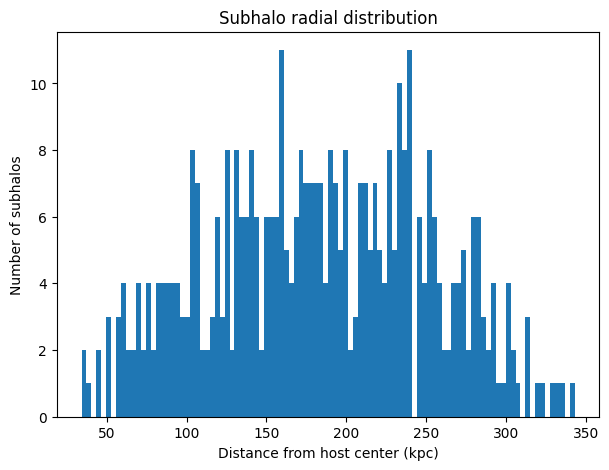

In [7]:
print(data.keys())
print(len(data["R_kpc"]))

for i in range(10):
    print(
        f"ID = {data['id'][i]:7d} | "
        f"Mass = {data['mass_msun'][i]:.2e} Msun | "
        f"R = {data['R_kpc'][i]:6.2f} kpc"
    )


plt.figure(figsize=(7,5))
plt.hist(data["R_kpc"], bins=100)
plt.xlabel("Distance from host center (kpc)")
plt.ylabel("Number of subhalos")
plt.title("Subhalo radial distribution")
plt.show()

In [8]:
"""
Stream ages (T_form) by length matching, for the six pipeline streams
(after Lu et al. 2026, Sec. 2.1).

Integrate the progenitor backwards for T_form in an MW potential, release
stars with the Fardal et al. (2015) spray, evolve to t = 0, and match the
simulated 10-90th-percentile length to the observed one. Keep the smallest
root, since length is non-monotonic once the stream wraps.

Differences from Lu et al.: progenitor is the galstreams track mid-point; no
IMF star counts or G < 20.7 cut; static MW potential, no LMC (poor for
Orphan-Chenab). Streams with unknown progenitor mass (Ylgr, C-12) are fit
over a mass grid and reported as a range.
"""

AGE_CACHE_DIR = Path("illustris_data/age_cache")
AGE_CACHE_VERSION = "v1"


def _age_cache_key(payload: dict) -> str:
    blob = json.dumps(payload, sort_keys=True)
    return hashlib.sha1(blob.encode()).hexdigest()[:20]


def _read_age_cache(payload: dict):
    f = AGE_CACHE_DIR / f"{_age_cache_key(payload)}.json"
    if f.exists():
        with open(f) as fp:
            return json.load(fp)
    return None


def _write_age_cache(payload: dict, data: dict) -> None:
    AGE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    with open(AGE_CACHE_DIR / f"{_age_cache_key(payload)}.json", "w") as fp:
        json.dump({"inputs": payload, **data}, fp, indent=2)


def cached_fit_age(H, w0, M_prog, M_prog0, ell_data_deg, e1, e2, *,
                   stream, dt_myr=2.0, mass_model="mean", seed=0,
                   refresh=False):
    """fit_age with a disk cache. Returns (T_gyr, status)."""

    payload = dict(
        version=AGE_CACHE_VERSION,
        stream=stream,
        M_prog=float(M_prog), M_prog0=float(M_prog0),
        ell_data_deg=round(float(ell_data_deg), 3),
        dt_myr=dt_myr, mass_model=mass_model, seed=seed,
        t_grid=T_GRID_GYR.tolist(),
        # The progenitor start point, so a changed galstreams track invalidates the cache
        w0=np.round(np.r_[np.ravel(w0.xyz.to(u.kpc).value),
                          np.ravel(w0.v_xyz.to(u.km / u.s).value)], 3).tolist(),
    )

    if not refresh:
        hit = _read_age_cache(payload)
        if hit is not None:
            print(f"{stream:14s} M_prog={M_prog:8.1e}  [cached] "
                  f"T_form = {hit['T_gyr']:.2f} Gyr ({hit['status']})")
            return hit["T_gyr"], hit["status"]

    T, status = fit_age(H, w0, M_prog, M_prog0, ell_data_deg, e1, e2,
                        dt_myr=dt_myr, mass_model=mass_model, seed=seed)
    _write_age_cache(payload, {"T_gyr": float(T), "status": status})
    print(f"{stream:14s} M_prog={M_prog:8.1e}  ell_data={ell_data_deg:5.1f} deg"
      f"  ->  T_form = {T:.2f} Gyr ({status})")
    return T, status


# ----------------------------------------------------------------------
# Per-stream configuration
# ----------------------------------------------------------------------
# Progenitor masses and observed lengths for the four validation streams are
# copied from Table 1 of Lu et al. 2026. Ylgr and C-12 are not in that paper,
# masses are unknown, so a grid is used, and the observed length is taken
# from the galstreams track unless overridden.
STREAMS = {
    "Indus-S19": dict(
        M_prog=6.5e6, M_prog0=0.0, ell_data_deg=72.0, lu2026_gyr=0.64,
        note="dwarf progenitor; real morphology more complex than the spray",
    ),
    "Jhelum-a-B19": dict(
        M_prog=1.3e7, M_prog0=0.0, ell_data_deg=23.0, lu2026_gyr=0.14,
        note="two-component stream; treat the fitted age as a lower bound",
    ),
    "NGC6397-I21": dict(
        M_prog=8.5e4, M_prog0=8.2e4, ell_data_deg=20.0, lu2026_gyr=0.13,
        note="GC progenitor, best constrained of the set",
    ),
    "Orphan-K23": dict(
        M_prog=1.1e6, M_prog0=0.0, ell_data_deg=76.0, lu2026_gyr=1.9,
        note="strongly perturbed by the LMC, which a static potential misses",
    ),
    "Ylgr-I21": dict(
        M_prog=None, M_prog0=0.0, ell_data_deg=45, lu2026_gyr=None,
        note="no progenitor mass or published age",
    ),
    "C-12-I24": dict(
        M_prog=None, M_prog0=0.0, ell_data_deg=None, lu2026_gyr=None,
        note="no progenitor mass, length or published age found",
    ),
}

# Used only for streams whose M_prog is None. Spans GC-like to small dwarf-like progenitors.
MASS_GRID_MSUN = [1e4, 1e5, 1e6]

# Trial ages (Gyr) scanned to bracket the root.
T_GRID_GYR = np.array([0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0])

# If the observed length must come from the galstreams track, the 90-10
# percentile length of the members is approximated as this fraction of the
# track's full extent (exact only for uniform star density).
TRACK_TO_PERCENTILE = 0.8


# ----------------------------------------------------------------------
# Pure-numpy geometry
# ----------------------------------------------------------------------
def unit_vectors(ra_rad: np.ndarray, dec_rad: np.ndarray) -> np.ndarray:
    ra_rad, dec_rad = np.asarray(ra_rad), np.asarray(dec_rad)
    return np.column_stack(
        [np.cos(dec_rad) * np.cos(ra_rad),
         np.cos(dec_rad) * np.sin(ra_rad),
         np.sin(dec_rad)]
    )


def great_circle_basis(track_vecs: np.ndarray):
    """Pole and in-plane axes of the best-fit great circle through the track.
    Returns (pole, e1, e2) with e1 pointing at the track mid-node, so
    phi1 = 0 at the middle of the track.
    """
    _, _, vt = np.linalg.svd(track_vecs, full_matrices=False)
    pole = vt[-1]
    mid = track_vecs[len(track_vecs) // 2]
    e1 = mid - np.dot(mid, pole) * pole
    e1 /= np.linalg.norm(e1)
    e2 = np.cross(pole, e1)
    return pole, e1, e2


def phi1_deg(vecs: np.ndarray, e1: np.ndarray, e2: np.ndarray) -> np.ndarray:
    """Angle along the great circle, in degrees, wrapped to [-180, 180]."""
    return np.degrees(np.arctan2(vecs @ e2, vecs @ e1))


def percentile_length_deg(phi1: np.ndarray, lo: float = 10, hi: float = 90) -> float:
    return float(np.percentile(phi1, hi) - np.percentile(phi1, lo))


def smallest_root(T: np.ndarray, f: np.ndarray, target: float):
    """Smallest T where f(T) crosses `target`, by linear interpolation.
    Returns (T_root, status) with status in {"ok", "below_grid", "not_reached"}.
    "below_grid": already longer than the data at the smallest trial age
    (true age is at most T[0]). "not_reached": never long enough by T[-1].
    """
    d = np.asarray(f) - target
    if d[0] >= 0:
        return float(T[0]), "below_grid"
    for i in range(1, len(T)):
        if d[i] >= 0:
            frac = -d[i - 1] / (d[i] - d[i - 1])
            return float(T[i - 1] + frac * (T[i] - T[i - 1])), "ok"
    return float(T[-1]), "not_reached"


# ----------------------------------------------------------------------
# galstreams helpers
# ----------------------------------------------------------------------
def _has_full_6d(sc) -> bool:
    """True if a SkyCoord has physical distance, proper motion and RV."""

    try:
        d = sc.distance.to(u.kpc).value
        pm1 = sc.pm_ra_cosdec.to(u.mas / u.yr).value
        pm2 = sc.pm_dec.to(u.mas / u.yr).value
        rv = sc.radial_velocity.to(u.km / u.s).value
    except Exception:
        return False
    return bool(np.all(np.isfinite([d, pm1, pm2, rv])))


def load_track(name: str, mws):
    """Return (track_icrs_nodes, progenitor_icrs_point) or raise KeyError."""

    if name not in mws.keys():
        close = [k for k in mws.keys() if name.split("-")[0].lower() in k.lower()]
        raise KeyError(f"{name!r} not in galstreams; similar names: {close}")
    track = mws[name]
    nodes = track.track.transform_to(coord.ICRS())
    mid = getattr(track, "mid_point", None)
    mid = nodes[len(nodes) // 2] if mid is None else mid.transform_to(coord.ICRS())
    return nodes, mid


# ----------------------------------------------------------------------
# gala simulation
# ----------------------------------------------------------------------
def make_hamiltonian():
    try:
        pot = gp.MilkyWayPotential(version="v2")
    except AttributeError:  # older gala
        print("MilkyWayPotential2022 unavailable; using MilkyWayPotential",
              file=sys.stderr)
        pot = gp.MilkyWayPotential()
    return gp.Hamiltonian(pot)


def simulate_phi1(H, w0, M_prog, M_prog0, T_gyr, e1, e2, *,
                  dt_myr=2.0, mass_model="mean", seed=0):
    """Phi1 (deg) of the simulated stream stars at t = 0 for age T_gyr."""

    n_steps = max(10, int(round(T_gyr * 1000.0 / dt_myr)))
    n_per_step = max(1, int(np.ceil(1000.0 / n_steps)))

    floor = 0.01 * M_prog
    if mass_model == "mean":
        mass = max(0.5 * (M_prog + M_prog0), floor) * u.Msun
    elif mass_model == "linear":
        # Linear in lookback time: M(T)=M_prog, M(0)=M_prog0 (gamma = 1).
        # ASSUMES the array is indexed in the same order gala steps in time;
        # verify on a known stream before relying on it.
        t_back = np.linspace(T_gyr, 0.0, n_steps + 1)
        m = M_prog0 + (M_prog - M_prog0) * t_back / T_gyr
        mass = np.maximum(m, floor) * u.Msun
    else:
        raise ValueError("mass_model must be 'mean' or 'linear'")

    np.random.seed(seed)
    df = ms.FardalStreamDF(gala_modified=True)
    gen = ms.MockStreamGenerator(df, H)
    stream, prog = gen.run(
        w0, mass, dt=-dt_myr * u.Myr, n_steps=n_steps, n_particles=n_per_step
    )

    # For a sanity check with dt < 0 the progenitor should END at w0. A mismatch
    # means gala's time-ordering differs from what this script assumes, so
    # warn loudly rather than silently returning wrong ages.
    try:
        end = np.asarray(prog.xyz.to(u.kpc).value).reshape(3, -1)[:, -1]
        sep = float(np.linalg.norm(end - np.asarray(w0.xyz.to(u.kpc).value).ravel()))
        if sep > 1.0:
            print(f"WARNING: progenitor ends {sep:.1f} kpc from w0; check gala's "
                  "time-ordering before trusting these ages", file=sys.stderr)
    except Exception:
        print("warning: could not verify progenitor endpoint", file=sys.stderr)

    sky = stream.to_coord_frame(
        coord.ICRS(), galactocentric_frame=coord.Galactocentric()
    )
    vecs = unit_vectors(sky.ra.rad, sky.dec.rad)
    return phi1_deg(vecs, e1, e2)


def fit_age(H, w0, M_prog, M_prog0, ell_data_deg, e1, e2, *,
            dt_myr=2.0, mass_model="mean", seed=0, n_bisect=5):
    """Smallest T_form with ell_sim(T_form) = ell_data. Returns (T, status)."""
    def ell(T):
        phi = simulate_phi1(H, w0, M_prog, M_prog0, T, e1, e2,
                            dt_myr=dt_myr, mass_model=mass_model, seed=seed)
        return percentile_length_deg(phi)

    ell_grid = np.array([ell(T) for T in T_GRID_GYR])
    T0, status = smallest_root(T_GRID_GYR, ell_grid, ell_data_deg)
    if status != "ok":
        return T0, status

    # Refine inside the bracketing grid interval by bisection.
    hi_idx = int(np.argmax(ell_grid >= ell_data_deg))
    lo, hi = float(T_GRID_GYR[hi_idx - 1]), float(T_GRID_GYR[hi_idx])
    for _ in range(n_bisect):
        mid = 0.5 * (lo + hi)
        if ell(mid) >= ell_data_deg:
            hi = mid
        else:
            lo = mid
    return 0.5 * (lo + hi), "ok"


# ----------------------------------------------------------------------
# Driver
# ----------------------------------------------------------------------
def fit_all_stream_ages(mass_model="mean", dt_myr=2.0, seed=0, refresh=False) -> pd.DataFrame:

    H = make_hamiltonian()
    mws = galstreams.MWStreams(verbose=False)
    rows = []

    for name, cfg in STREAMS.items():
        row = dict(stream=name, lu2026_gyr=cfg["lu2026_gyr"], note=cfg["note"])
        try:
            nodes, mid = load_track(name, mws)
        except KeyError as e:
            row.update(status=f"track missing: {e}")
            rows.append(row)
            continue

        if not _has_full_6d(mid):
            row.update(status="skipped: progenitor point lacks 6D data")
            rows.append(row)
            continue

        vecs = unit_vectors(nodes.ra.rad, nodes.dec.rad)
        _, e1, e2 = great_circle_basis(vecs)

        ell_data = cfg["ell_data_deg"]
        if ell_data is None:
            phi = phi1_deg(vecs, e1, e2)
            ell_data = TRACK_TO_PERCENTILE * float(np.ptp(phi))
            row["ell_source"] = f"galstreams track x {TRACK_TO_PERCENTILE}"
        else:
            row["ell_source"] = "Lu+2026 Table 1 / literature"
        row["ell_data_deg"] = ell_data

        w0 = gd.PhaseSpacePosition(mid.transform_to(coord.Galactocentric()).data)

        masses = [cfg["M_prog"]] if cfg["M_prog"] is not None else MASS_GRID_MSUN
        ages, statuses = [], []
        for M in masses:
          T, status = cached_fit_age(
          H, w0, M, cfg["M_prog0"], ell_data, e1, e2,
          stream=name, dt_myr=dt_myr, mass_model=mass_model,
          seed=seed, refresh=refresh,
          )
          ages.append(T)
          statuses.append(status)

        row.update(
            age_gyr=float(np.median(ages)),
            age_min_gyr=float(np.min(ages)),
            age_max_gyr=float(np.max(ages)),
            status="/".join(sorted(set(statuses))),
        )
        rows.append(row)

    return pd.DataFrame(rows).set_index("stream")


def to_age_dict(df: pd.DataFrame) -> dict:
    """STREAM_AGE_GYR for the pipeline.
    Published Lu+2026 age where one exists, otherwise the fitted age
    (only if status is ok), otherwise None.
    """
    out = {}
    for name, cfg in STREAMS.items():
        if cfg["lu2026_gyr"] is not None:        # published value wins
            out[name] = cfg["lu2026_gyr"]
            continue
        ok = name in df.index and df.loc[name].get("status") == "ok"
        out[name] = round(float(df.loc[name, "age_gyr"]), 2) if ok else None
    return out


def print_validation(results: pd.DataFrame):     # to compare age_gyr with lu2026_gyr
    pd.set_option("display.width", 200)
    cols = ["lu2026_gyr", "age_gyr", "age_min_gyr", "age_max_gyr",
            "ell_data_deg", "status"]
    print("\n", results[[c for c in cols if c in results.columns]].round(2))
    print("\nSTREAM_AGE_GYR =", to_age_dict(results))

In [9]:
"""
Per-stream subhalo encounter rates for TNG Milky Way analogues.

1. Orbit: integrate the galstreams 6D anchor for 5 Gyr in MilkyWayPotential
   v2; r_inner = pericenter, r_outer = apocenter, v_rel = peak speed.
   Streams without real 6D data are skipped and reported.
2. Age: from fit_all_stream_ages, validated against Lu et al. 2026.
   Streams without an age are skipped.
3. Subhalo speed: each subhalo's velocity relative to its host, from TNG.
4. Rate per halo: sum_i(b_max,i * v_i) / V_shell * t_age, with
   b_max = 5 r_s, r_s = 1.05 kpc * sqrt(M / 1e8 Msun). Zeros are kept so
   n_halos is the same for all streams; report the median and 16th/84th
   percentiles.
"""

# -----------------------------------------------------------------------
# 1. Per-stream orbital range and rel. velocity, derived from galstreams + gala
# -----------------------------------------------------------------------
# Map stream_id to galstreams track name
STREAM_IDS = {
    15: "Indus-S19",
    20: "C-12-I24",
    41: "Ylgr-I21",
    48: "Orphan-K23",
    69: "NGC6397-I21",
    86: "Jhelum-a-B19",
}

_POTENTIAL = gp.MilkyWayPotential(version="v2") # Using the standard gala MW mass model

def get_stream_orbital_params(track_name, mws, integration_time_gyr=5.0, n_steps=5000):
    """
    Derive (r_inner, r_outer, v_characteristic) for a stream by integrating
    its orbit in a Milky Way potential, using galstreams' track data as the
    present-day phase-space anchor.

    Returns None if the track doesn't have full 6D data (proper motion +
    distance + line-of-sight velocity) needed to define an orbit.
    """

    if track_name not in mws.keys():
        return None, f"track name '{track_name}' not in galstreams keys"

    sc = mws[track_name].track

    # Missing distance shows up as a dimensionless placeholder, not an error
    try:
        if sc.distance.unit.physical_type != "length":
            return None, "no distance in track"
        pm_ra, pm_dec, rv = sc.pm_ra_cosdec, sc.pm_dec, sc.radial_velocity
    except Exception as e:
        return None, f"missing PM/RV data ({type(e).__name__})"

    # Placeholder check: all-zero RV or PM means the data is not real
    if np.all(rv.value == 0) or (np.all(pm_ra.value == 0) and np.all(pm_dec.value == 0)):
        return None, "RV/PM are placeholders (all zero)"

    gc = sc.transform_to(coord.Galactocentric())
    vx = gc.v_x.to_value(u.km / u.s)
    good = np.where(np.isfinite(gc.x.value) & np.isfinite(vx))[0]
    if len(good) == 0:
        return None, "no track points with finite 6D phase-space values"

    i = good[len(good) // 2]
    w0 = gd.PhaseSpacePosition(gc[i].data)

    orbit = _POTENTIAL.integrate_orbit(
        w0, dt=integration_time_gyr / n_steps * u.Gyr, n_steps=n_steps
    )
    speeds = np.linalg.norm(orbit.v_xyz.to_value(u.km / u.s), axis=0)
    return {
        "r_inner": orbit.pericenter().to_value(u.kpc),
        "r_outer": orbit.apocenter().to_value(u.kpc),
        "v_rel": speeds.max(),
    }, None



fit_results = fit_all_stream_ages()
print_validation(fit_results)
STREAM_AGE_GYR = to_age_dict(fit_results)


# -----------------------------------------------------------------------
# 2. Perturbation-rate calculation
# -----------------------------------------------------------------------

def compute_perturbation_rate(
    masses_msun: np.ndarray,
    radii_kpc: np.ndarray,
    rel_speeds_kms: np.ndarray,
    r_inner: float,
    r_outer: float,
    stream_age_gyr: float,
    bmax_factor: float = 5.0,
) -> float:
    """
    Perturbations-per-kpc for ONE halo, using:
      - this stream's own [r_inner, r_outer] shell (from its real orbit), and
      - each subhalo's own relative speed (from TNG kinematics)
    """
    mask = (radii_kpc >= r_inner) & (radii_kpc <= r_outer)
    if mask.sum() == 0:
        return 0.0

    masses = masses_msun[mask]
    speeds = rel_speeds_kms[mask]  # km/s, per-subhalo

    kpc_per_kms_gyr = 1.022712
    speeds_kpc_gyr = speeds * kpc_per_kms_gyr

    rs = 1.05 * np.sqrt(masses / 1e8)
    bmax = bmax_factor * rs

    shell_volume = (4 / 3) * np.pi * (r_outer**3 - r_inner**3)
    encounter_rate = np.sum(bmax * speeds_kpc_gyr) / shell_volume

    return encounter_rate * stream_age_gyr


# -----------------------------------------------------------------------
# 3. Orchestration (running all functions)
# -----------------------------------------------------------------------

def run_all_streams(all_halos):
    mws = galstreams.MWStreams(verbose=False)
    rows, per_halo = [], {}
    for stream_id, name in STREAM_IDS.items():
        params, why = get_stream_orbital_params(name, mws)
        age = STREAM_AGE_GYR.get(name)
        if params is None or age is None:
            print(f"{name}: skipped -- {why if params is None else 'no age'}")
            continue
        ids, rates = [], []
        for idx, h in all_halos.items():
            r = compute_perturbation_rate(h["mass_msun"], h["R_kpc"], h["rel_speed_kms"],
                                          params["r_inner"], params["r_outer"], age)
            ids.append(idx); rates.append(r)
        arr = np.array(rates)
        per_halo[name] = pd.DataFrame({"halo_id": ids, "rate": arr})
        rows.append({"stream": name, **params, "stream_age_gyr": age,
                     "median": np.median(arr),
                     "pctile_16": np.percentile(arr, 16),
                     "pctile_84": np.percentile(arr, 84),
                     "mean": arr.mean(),
                     "n_halos": len(arr),
                     "n_halos_nonzero": int((arr > 0).sum()),
                     "frac_halos_nonzero": float(np.mean(arr > 0))})
    return pd.DataFrame(rows).set_index("stream"), per_halo


def plot_streams(summary_df, per_halo, bins=25):
    for name, df in per_halo.items():
        row = summary_df.loc[name]
        plt.figure(figsize=(8, 5))
        plt.hist(df["rate"], bins=bins)
        plt.axvline(row["median"], color="red", lw=2, label="Median")
        plt.axvline(row["pctile_16"], color="k", ls="--", label="16th")
        plt.axvline(row["pctile_84"], color="k", ls="--", label="84th")
        plt.xlabel("Perturbations per kpc"); plt.ylabel("Number of MW analogues")
        plt.title(f"{name} (r = {row.r_inner:.0f}–{row.r_outer:.0f} kpc, age = {row.stream_age_gyr:.1f} Gyr)")
        plt.legend(); plt.show()


def main():
    halo_indices = find_mw_halos()
    all_halos = {i: fetch_subhalos(i, verbose=False) for i in halo_indices}
    summary_df, per_halo = run_all_streams(all_halos)
    print(summary_df)
    plot_streams(summary_df, per_halo)
    return all_halos, summary_df, per_halo

Initializing galstreams library from master_log... 
Indus-S19      M_prog= 6.5e+06  ell_data= 72.0 deg  ->  T_form = 0.93 Gyr (ok)
Jhelum-a-B19   M_prog= 1.3e+07  ell_data= 23.0 deg  ->  T_form = 0.21 Gyr (ok)
NGC6397-I21    M_prog= 8.5e+04  ell_data= 20.0 deg  ->  T_form = 0.15 Gyr (ok)
Orphan-K23     M_prog= 1.1e+06  ell_data= 76.0 deg  ->  T_form = 1.74 Gyr (ok)
Ylgr-I21       M_prog= 1.0e+04  ell_data= 45.0 deg  ->  T_form = 2.58 Gyr (ok)
Ylgr-I21       M_prog= 1.0e+05  ell_data= 45.0 deg  ->  T_form = 1.18 Gyr (ok)
Ylgr-I21       M_prog= 1.0e+06  ell_data= 45.0 deg  ->  T_form = 0.54 Gyr (ok)
C-12-I24       M_prog= 1.0e+04  ell_data= 22.3 deg  ->  T_form = 0.22 Gyr (ok)
C-12-I24       M_prog= 1.0e+05  ell_data= 22.3 deg  ->  T_form = 0.13 Gyr (ok)
C-12-I24       M_prog= 1.0e+06  ell_data= 22.3 deg  ->  T_form = 0.07 Gyr (ok)

               lu2026_gyr  age_gyr  age_min_gyr  age_max_gyr  ell_data_deg status
stream                                                                     

Initializing galstreams library from master_log... 
                r_inner    r_outer       v_rel  stream_age_gyr    median  pctile_16  pctile_84      mean  n_halos  n_halos_nonzero  frac_halos_nonzero
stream                                                                                                                                                
Indus-S19     13.530618  25.300034  281.107348            0.64  0.007716   0.000000   0.032564  0.017083      103               53            0.514563
C-12-I24       1.003375  10.336535  456.562845            0.13  0.000000   0.000000   0.000000  0.003404      103                6            0.058252
Ylgr-I21       9.119041  20.404723  310.365859            1.18  0.000000   0.000000   0.064576  0.029199      103               35            0.339806
Orphan-K23    15.235592  45.920124  324.371620            1.90  0.032325   0.012078   0.056500  0.036947      103              101            0.980583
NGC6397-I21    2.767267   6.482314  327.78

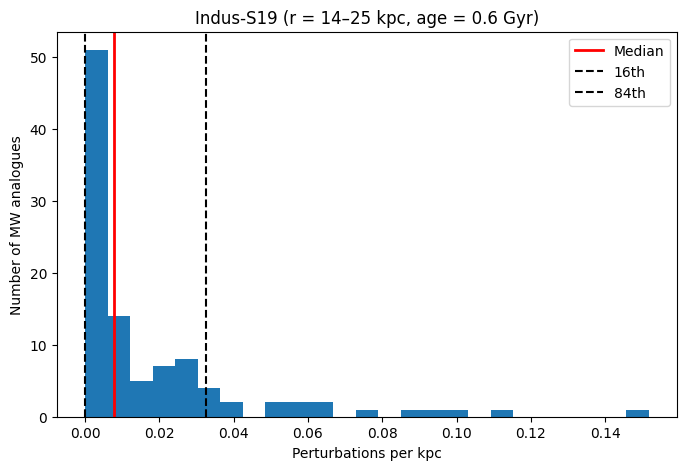

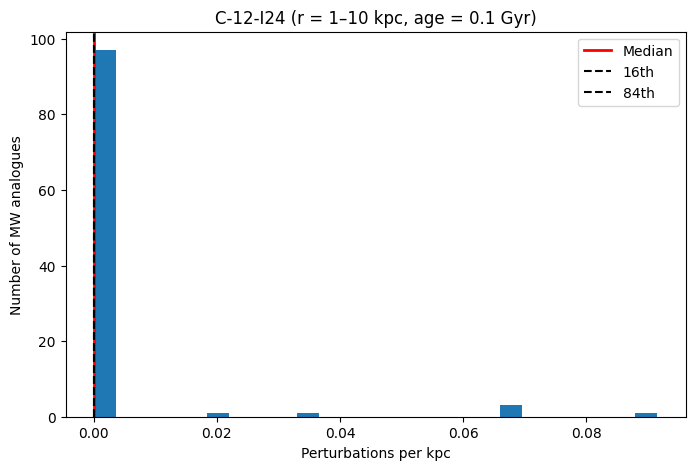

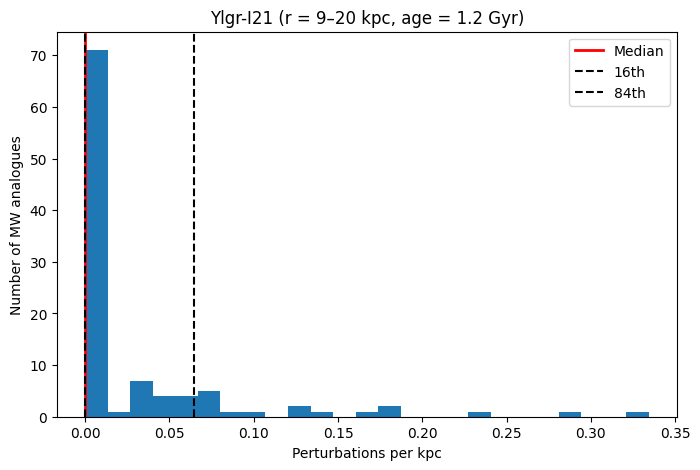

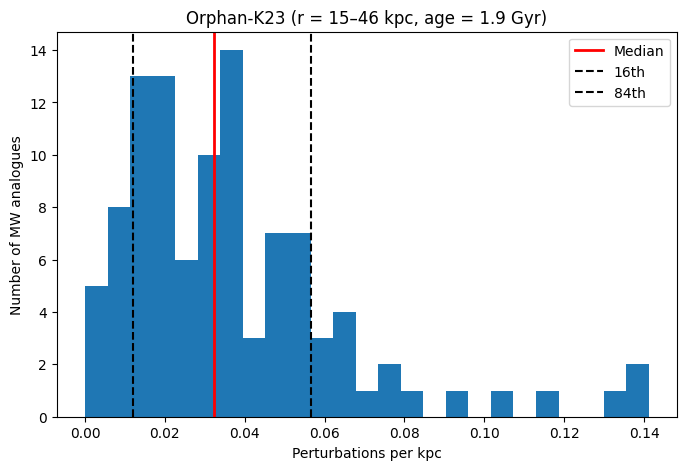

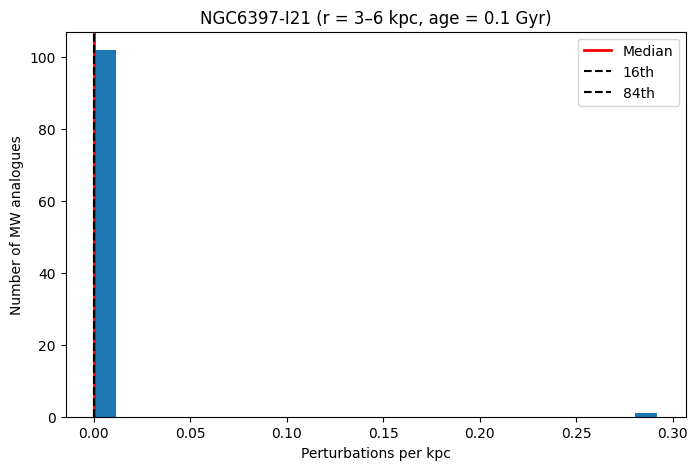

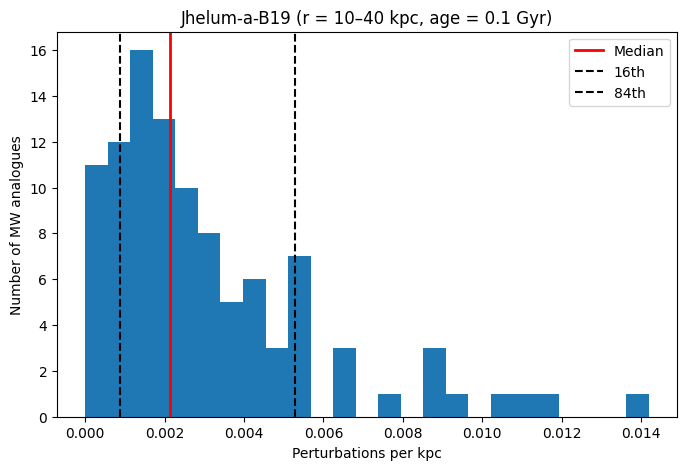

In [10]:
all_halos, summary_df, per_halo = main()